# U-Chrom Imaging Pipeline

Data moves through memory by default. Set `SAVE_MODE` to save selected or pyHiM-style artifacts under `OUT_DIR`.

## Section 1: Load Raw Data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import shift as shift_image
import importlib
import uchrom.im.compare as im_compare
im_compare = importlib.reload(im_compare)

from uchrom.im import (
    ImWorkspace,
    plot_registration_qc_arrays,
    segment,
    localize,
    filter_localizations,
    register_localizations,
    build_traces,
    build_matrix,
)
from uchrom.im.compare import (
    finite_array_metrics,
    first_existing,
    foreground_scores,
    label_iou_matches,
    localization_count_summary,
    mask_summary,
    match_localizations_by_position,
    matrix_metrics,
    plot_localization_xy,
    read_ecsv,
    show_array_comparison,
    show_barcode_localization_qc,
    show_mask_overlay,
    show_mask_segmentation_qc,
    show_matrix_comparison,
    show_local_registration_3d_qc,
    show_localization_match_diagnostics,
    show_registration_qc_comparison,
    trace_summary,
)

RAW_DIR = Path(r"F:/project/Caolab/U-C-p/UC/test_data/raw")
OUT_DIR = Path(r"F:/project/Caolab/U-C-p/UC/test_data")
PYHIM_DIR = Path(r"F:/project/Caolab/U-C-p/pyHiM/test/test_dataset")
PYHIM_ANALYSIS_DIR = PYHIM_DIR / "analysis_localizations"

SAVE_MODE = False      # False, "selected", or "all"
SAMPLE_ID = "scan_001"
ROI = "005"
REFERENCE_ROUND = "RT26"
Z_BINNING = 2
# Format: (y0, y1, x0, x1). Use None to show the full field of view.
REGISTRATION_QC_ZOOM = (300, 700, 300, 700)
# Block-window format: (row0, row1, col0, col1). Use None for full field of view.
LOCAL_REGISTRATION_3D_QC_ROUND = "RT27"
LOCAL_REGISTRATION_3D_QC_BLOCK_WINDOW = None
LOCAL_REGISTRATION_3D_QC_Z_CROP = None  # Format: (y0, y1, x0, x1) for Z-projection only.
# pyHiM register_localizations defaults: anisotropic tolerance in (z, y-row, x-col) shift axes.
LOCALIZATION_TOLERANCE_DRIFT = (3, 1, 1)
REMOVE_UNCORRECTED_LOCALIZATIONS = True
SEGMENTATION_QC_CROP = None  # Format: (y0, y1, x0, x1).
LOCALIZATION_QC_CROP = None  # Format: (y0, y1, x0, x1).

manifest = {
    "RT26": {
        "fiducial": {"path": RAW_DIR / "scan_001_RT26_005_ROI_converted_decon_ch00.tif"},
        "images": {"barcode": {"path": RAW_DIR / "scan_001_RT26_005_ROI_converted_decon_ch01.tif"}},
        "meta": {"sample_id": SAMPLE_ID, "roi": ROI},
    },
    "RT27": {
        "fiducial": {"path": RAW_DIR / "scan_001_RT27_005_ROI_converted_decon_ch00.tif"},
        "images": {"barcode": {"path": RAW_DIR / "scan_001_RT27_005_ROI_converted_decon_ch01.tif"}},
        "meta": {"sample_id": SAMPLE_ID, "roi": ROI},
    },
    "DAPI": {
        "fiducial": {"path": RAW_DIR / "scan_001_DAPI_005_ROI_converted_decon_ch01.tif"},
        "images": {"dapi": {"path": RAW_DIR / "scan_001_DAPI_005_ROI_converted_decon_ch00.tif"}},
        "meta": {"sample_id": SAMPLE_ID, "roi": ROI},
    },
}

workspace = ImWorkspace.from_manifest(manifest, meta={"sample_id": SAMPLE_ID, "roi": ROI})
list(workspace.raw_rounds)


d:\Miniconda3\envs\uchrom\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['RT26', 'RT27', 'DAPI']

In [2]:
workspace.raw_rounds["RT26"]["fiducial"].data.shape

(70, 1024, 1024)

In [3]:
workspace

ImWorkspace(raw_rounds={'RT26': {'fiducial': Image3D(data=array([[[69, 67, 66, ..., 74, 73, 75],
        [68, 66, 66, ..., 70, 68, 68],
        [69, 67, 67, ..., 69, 67, 67],
        ...,
        [73, 77, 78, ..., 45, 46, 47],
        [69, 72, 74, ..., 46, 46, 47],
        [68, 71, 72, ..., 50, 49, 47]],

       [[66, 65, 62, ..., 83, 78, 76],
        [64, 64, 64, ..., 80, 75, 73],
        [61, 62, 65, ..., 77, 73, 73],
        ...,
        [73, 80, 80, ..., 48, 49, 47],
        [69, 74, 74, ..., 47, 47, 46],
        [68, 71, 70, ..., 47, 46, 44]],

       [[63, 64, 61, ..., 87, 79, 72],
        [62, 65, 66, ..., 82, 73, 67],
        [62, 66, 71, ..., 80, 71, 66],
        ...,
        [79, 81, 78, ..., 53, 53, 53],
        [75, 76, 75, ..., 50, 51, 52],
        [71, 72, 73, ..., 46, 47, 49]],

       ...,

       [[45, 45, 48, ..., 57, 57, 53],
        [46, 46, 48, ..., 58, 58, 55],
        [49, 48, 49, ..., 58, 59, 56],
        ...,
        [50, 46, 43, ..., 48, 52, 58],
        [46, 

## Section 1.5: pyHiM Comparison Setup

The comparison cells use pyHiM outputs as references. Metrics are chosen by data type: pixel-wise metrics for arrays, label-aware IoU for masks, coordinate nearest-neighbor matching for localizations, and summary/matrix comparisons for traces.


In [4]:
PYHIM_PROJECT_DATA = PYHIM_DIR / "project" / "data"
PYHIM_REGISTER_GLOBAL_DATA = PYHIM_DIR / "register_global" / "data"
PYHIM_REGISTER_LOCAL_DATA = PYHIM_DIR / "register_local" / "data"
PYHIM_MASK_2D_DATA = PYHIM_DIR / "mask_2d" / "data"
PYHIM_MASK_3D_DATA = PYHIM_DIR / "mask_3d" / "data"
PYHIM_LOCALIZE_3D_PATH = first_existing(
    PYHIM_ANALYSIS_DIR / "localize_3d" / "data" / "localizations_3D_barcode.dat",
    PYHIM_DIR / "localize_3d" / "data" / "localizations_3D_barcode.dat",
)
PYHIM_TRACE_DATA = PYHIM_ANALYSIS_DIR / "tracing" / "data"

comparison_paths = {
    "project": PYHIM_PROJECT_DATA,
    "register_global": PYHIM_REGISTER_GLOBAL_DATA,
    "register_local": PYHIM_REGISTER_LOCAL_DATA,
    "mask_2d": PYHIM_MASK_2D_DATA,
    "mask_3d": PYHIM_MASK_3D_DATA,
    "localize_3d": PYHIM_LOCALIZE_3D_PATH,
    "tracing": PYHIM_TRACE_DATA,
}
comparison_paths


{'project': WindowsPath('F:/project/Caolab/U-C-p/pyHiM/test/test_dataset/project/data'),
 'register_global': WindowsPath('F:/project/Caolab/U-C-p/pyHiM/test/test_dataset/register_global/data'),
 'register_local': WindowsPath('F:/project/Caolab/U-C-p/pyHiM/test/test_dataset/register_local/data'),
 'mask_2d': WindowsPath('F:/project/Caolab/U-C-p/pyHiM/test/test_dataset/mask_2d/data'),
 'mask_3d': WindowsPath('F:/project/Caolab/U-C-p/pyHiM/test/test_dataset/mask_3d/data'),
 'localize_3d': WindowsPath('F:/project/Caolab/U-C-p/pyHiM/test/test_dataset/analysis_localizations/localize_3d/data/localizations_3D_barcode.dat'),
 'tracing': WindowsPath('F:/project/Caolab/U-C-p/pyHiM/test/test_dataset/analysis_localizations/tracing/data')}

## Section 2: Projection

In [5]:
projection_methods = {
    "RT26": {"fiducial": "mip", "barcode": "mip"},
    "RT27": {"fiducial": "mip", "barcode": "mip"},
    "DAPI": {"fiducial": "mip", "dapi": "sum"},
}

projection_z_ranges = {
    "RT26": {"fiducial": (1, 70), "barcode": (1, 70)},
    "RT27": {"fiducial": (1, 70), "barcode": (1, 70)},
    "DAPI": {"fiducial": (1, 70), "dapi": (1, 70)},
}

workspace.project(methods=projection_methods, z_ranges=projection_z_ranges)

if SAVE_MODE:
    workspace.save("project", OUT_DIR / "project", mode=SAVE_MODE)

{round_name: spec["fiducial"].data.shape for round_name, spec in workspace.projections.items()}

{'RT26': (1024, 1024), 'RT27': (1024, 1024), 'DAPI': (1024, 1024)}

### pyHiM Projection Comparison

Projection is the strictest comparison. If the same z-range and projection method are used, shapes should match and pixel differences should be near zero.


,shape_reference,shape_candidate,dtype_reference,dtype_candidate,shape_match,finite_fraction,exact_equal,max_abs_diff,mean_abs_diff,rmse,nrmse_by_ref_range,pearson,round,role,status,path
0,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT26,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
1,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT26,barcode,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
2,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT27,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
3,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT27,barcode,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
4,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,DAPI,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
5,"(1024, 1024)","(1024, 1024)",float64,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,DAPI,dapi,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...


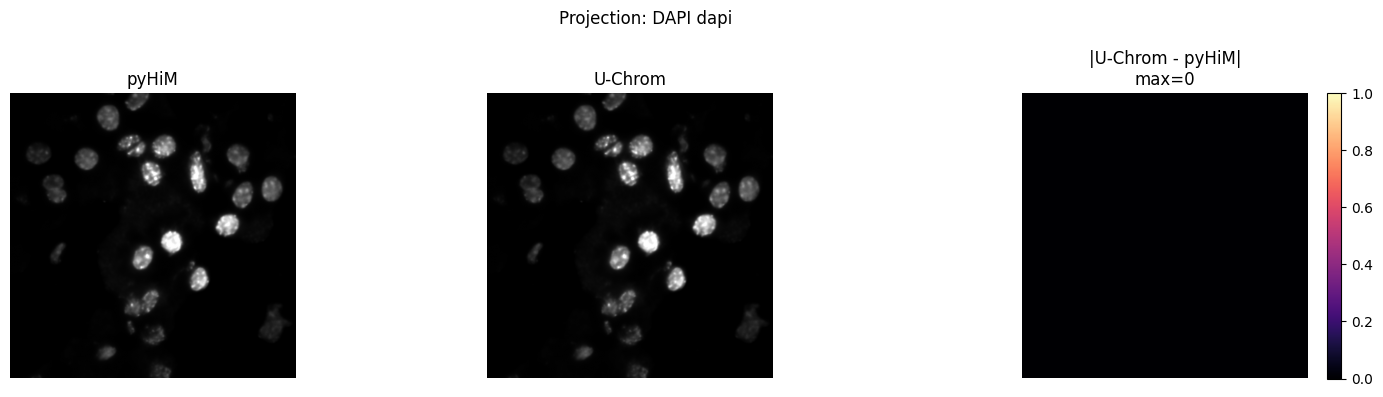

In [6]:
projection_rows = []
projection_examples = []
for round_name, spec in workspace.projections.items():
    for role, image in [("fiducial", spec["fiducial"])] + list(spec.get("images", {}).items()):
        pyhim_path = PYHIM_PROJECT_DATA / f"{image.name}.npy"
        if not pyhim_path.exists():
            projection_rows.append({"round": round_name, "role": role, "status": "missing", "path": str(pyhim_path)})
            continue
        pyhim_array = np.load(pyhim_path)
        row = finite_array_metrics(pyhim_array, image.data)
        row.update({"round": round_name, "role": role, "status": "ok", "path": str(pyhim_path)})
        projection_rows.append(row)
        projection_examples.append((round_name, role, pyhim_array, image.data))

display(pd.DataFrame(projection_rows))
if projection_examples:
    preferred = next(
        (example for example in projection_examples if example[0] == "DAPI" and example[1] == "dapi"),
        projection_examples[0],
    )
    round_name, role, pyhim_array, uchrom_array = preferred
    show_array_comparison(pyhim_array, uchrom_array, title=f"Projection: {round_name} {role}")


## Section 3: 2D Global Registration

In [7]:
workspace.register_global(
    reference=REFERENCE_ROUND,
    sample_id=SAMPLE_ID,
    roi=ROI,
    upsample_factor=100,
    align_by_block=True,
    block_size=128,
    tolerance=0.1,
    background_sigma=3.0,
)

if SAVE_MODE:
    workspace.save("register_global", OUT_DIR / "register_global", mode=SAVE_MODE)

{name: result.shift.tolist() for name, result in workspace.global_registration.rounds.items()}


{'RT26': [0.0, 0.0],
 'RT27': [5.114090897820213, -6.615454543720592],
 'DAPI': [-32.63235327776741, 19.282352784100702]}

### pyHiM 2D Global Registration Comparison

Registered images are compared pixel-wise. Shifts are compared from `shifts.json` because matching image artifacts alone can hide a wrong transform.


,shape_reference,shape_candidate,dtype_reference,dtype_candidate,shape_match,finite_fraction,exact_equal,max_abs_diff,mean_abs_diff,rmse,nrmse_by_ref_range,pearson,round,role,status,path
0,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT26,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
1,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT26,barcode,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
2,"(1024, 1024)","(1024, 1024)",float32,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT27,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
3,"(1024, 1024)","(1024, 1024)",uint16,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,RT27,barcode,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
4,"(1024, 1024)","(1024, 1024)",float32,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,DAPI,fiducial,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...
5,"(1024, 1024)","(1024, 1024)",float64,float64,True,1.0,True,0.0,0.0,0.0,0.0,1.0,DAPI,dapi,ok,F:\project\Caolab\U-C-p\pyHiM\test\test_datase...


,round,pyhim_0,pyhim_1,uchrom_0,uchrom_1,delta_norm
0,RT27,5.114091,-6.615455,5.114091,-6.615455,0.0
1,DAPI,-32.632353,19.282353,-32.632353,19.282353,0.0


(<Figure size 1500x800 with 6 Axes>,
 array([[<Axes: title={'center': 'Uncorrected'}, ylabel='U-Chrom'>,
         <Axes: title={'center': 'Corrected'}>,
         <Axes: title={'center': 'Overlay'}>],
        [<Axes: ylabel='pyHiM'>, <Axes: >, <Axes: >]], dtype=object))

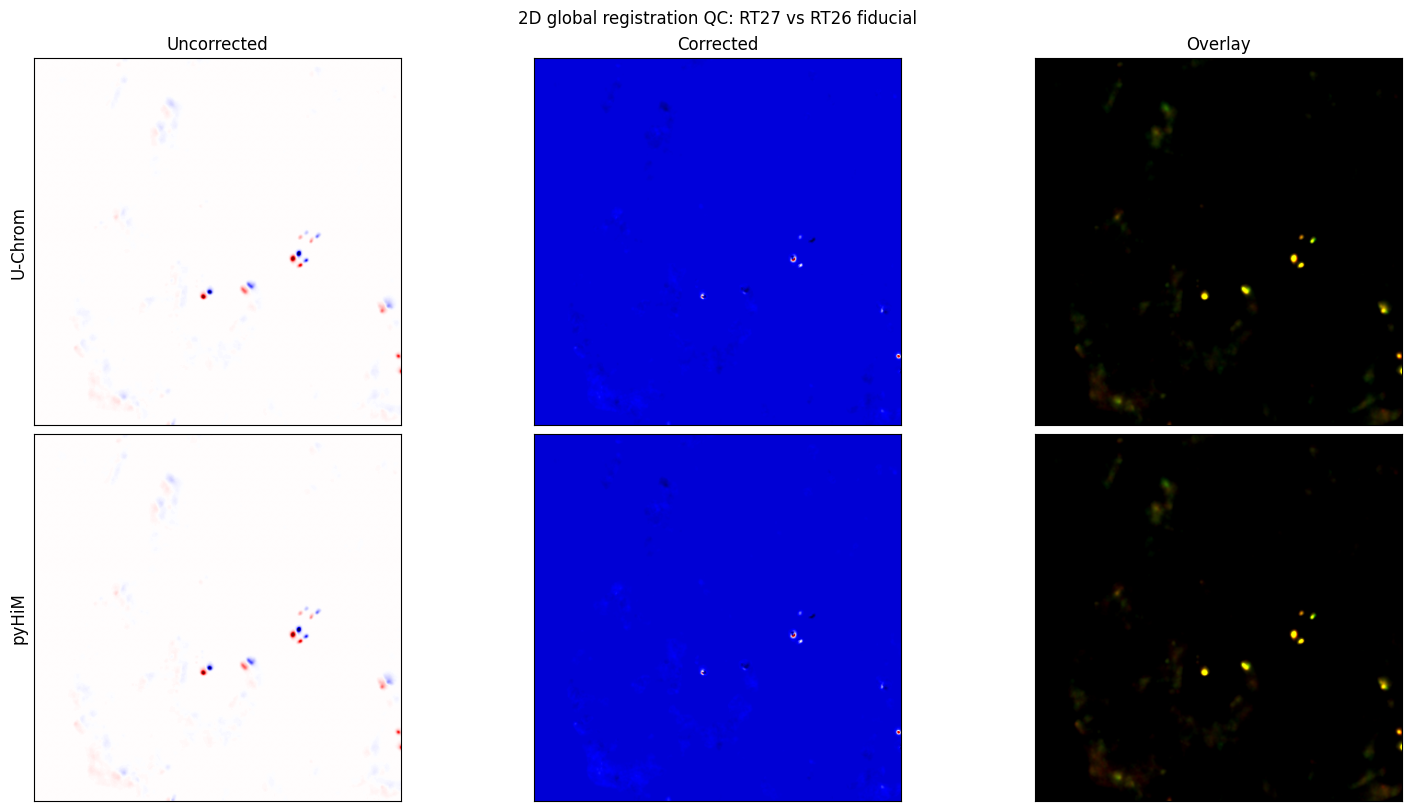

In [8]:
registration_rows = []
registration_examples = []
for round_name, rr in workspace.global_registration.rounds.items():
    candidates = [("fiducial", rr.fiducial.name, rr.registered_fiducial)]
    candidates += [(name, ir.input_image.name, ir.registered) for name, ir in rr.images.items()]
    for role, stem, array in candidates:
        pyhim_path = PYHIM_REGISTER_GLOBAL_DATA / f"{stem}_registered.npy"
        if not pyhim_path.exists():
            registration_rows.append({"round": round_name, "role": role, "status": "missing", "path": str(pyhim_path)})
            continue
        pyhim_array = np.load(pyhim_path)
        row = finite_array_metrics(pyhim_array, array)
        row.update({"round": round_name, "role": role, "status": "ok", "path": str(pyhim_path)})
        registration_rows.append(row)
        registration_examples.append((round_name, role, pyhim_array, array))

display(pd.DataFrame(registration_rows))

shift_path = PYHIM_REGISTER_GLOBAL_DATA / "shifts.json"
if shift_path.exists():
    pyhim_payload = json.loads(shift_path.read_text(encoding="utf-8"))
    pyhim_shifts = pyhim_payload.get(f"ROI:{ROI}", pyhim_payload)
    shift_rows = []
    for round_name, rr in workspace.global_registration.rounds.items():
        if round_name == workspace.global_registration.reference or round_name not in pyhim_shifts:
            continue
        py = np.asarray(pyhim_shifts[round_name], dtype=float)
        uc = np.asarray(rr.shift, dtype=float)
        shift_rows.append({"round": round_name, "pyhim_0": py[0], "pyhim_1": py[1], "uchrom_0": uc[0], "uchrom_1": uc[1], "delta_norm": float(np.linalg.norm(uc - py))})
    display(pd.DataFrame(shift_rows))

show_registration_qc_comparison(
    workspace.global_registration,
    moving_round="RT27",
    pyhim_project_data=PYHIM_PROJECT_DATA,
    pyhim_register_global_data=PYHIM_REGISTER_GLOBAL_DATA,
    reference_round=REFERENCE_ROUND,
    zoom=REGISTRATION_QC_ZOOM,
    overlay_gain=5.0,
    background_sigma=3.0,
)


## Section 4: 3D Local Registration

In [9]:
workspace.register_local(
    reference=REFERENCE_ROUND,
    method="block3d",
    block_size_xy=128,
    upsample_factor=100,
    lower_threshold=0.9,
    higher_threshold=0.9999,
    pixel_size_xy=0.1,
    pixel_size_z=0.25,
    z_binning=2,
)

if SAVE_MODE:
    workspace.save("register_local", OUT_DIR / "register_local", mode=SAVE_MODE)

workspace.local_registration.table.head()


d:\Miniconda3\envs\uchrom\lib\site-packages\skimage\registration\_phase_cross_correlation.py:112: RuntimeWarning: invalid value encountered in scalar divide
  error = 1.0 - cross_correlation_max * cross_correlation_max.conj() /\
d:\Miniconda3\envs\uchrom\lib\site-packages\skimage\registration\_phase_cross_correlation.py:112: RuntimeWarning: invalid value encountered in scalar divide
  error = 1.0 - cross_correlation_max * cross_correlation_max.conj() /\
d:\Miniconda3\envs\uchrom\lib\site-packages\skimage\registration\_phase_cross_correlation.py:112: RuntimeWarning: divide by zero encountered in scalar divide
  error = 1.0 - cross_correlation_max * cross_correlation_max.conj() /\


,reference file,aligned file,blockXY,ROI #,label,block_i,block_j,shift_z,shift_x,shift_y,quality_xy,quality_zy,quality_zx
0,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_RT27_005_ROI_converted_decon_ch00.tif,128,5,RT27,0,0,7.97,43.189999,-47.970001,1.069537,1.091496,1.071822
1,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_RT27_005_ROI_converted_decon_ch00.tif,128,5,RT27,0,1,-0.22,-0.050000,-1.420000,0.679322,0.749728,0.677248
2,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_RT27_005_ROI_converted_decon_ch00.tif,128,5,RT27,0,2,0.04,-0.080000,0.000000,0.384005,0.507052,0.440670
3,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_RT27_005_ROI_converted_decon_ch00.tif,128,5,RT27,0,3,0.04,-0.160000,-0.020000,0.663053,0.693157,0.742731
4,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_RT27_005_ROI_converted_decon_ch00.tif,128,5,RT27,0,4,1.02,0.920000,-1.090000,1.006137,0.937474,0.974174


### pyHiM 3D Local Registration Comparison

The quantitative target for local registration is the block shift table. Blocks are matched by aligned file, ROI and block indices. The projection QC below follows pyHiM visual semantics: red is the reference fiducial, green is the moving fiducial after block-wise 3D correction, blue is the block grid, and yellow means red/green overlap.


In [10]:
pyhim_local_path = PYHIM_REGISTER_LOCAL_DATA / "shifts_block3D.dat"
if pyhim_local_path.exists() and workspace.local_registration is not None:
    pyhim_local = read_ecsv(pyhim_local_path)
    uchrom_local = workspace.local_registration.table.copy()
    for table in (pyhim_local, uchrom_local):
        for col in ["aligned file", "reference file", "label"]:
            if col in table: table[col] = table[col].astype(str)
        for col in ["ROI #", "block_i", "block_j", "shift_z", "shift_x", "shift_y", "quality_xy", "quality_zy", "quality_zx"]:
            if col in table: table[col] = pd.to_numeric(table[col], errors="coerce")
    keys = [c for c in ["aligned file", "ROI #", "block_i", "block_j"] if c in pyhim_local and c in uchrom_local]
    merged = pyhim_local.merge(uchrom_local, on=keys, suffixes=("_pyhim", "_uchrom"))
    display(pd.DataFrame([{"source":"pyHiM", "rows":len(pyhim_local)}, {"source":"U-Chrom", "rows":len(uchrom_local)}, {"source":"matched blocks", "rows":len(merged)}]))
    rows = []
    for axis in ["shift_z", "shift_x", "shift_y"]:
        a, b = f"{axis}_pyhim", f"{axis}_uchrom"
        if a in merged and b in merged:
            delta = merged[b] - merged[a]
            rows.append({"axis": axis, "mean_abs_delta_px": float(delta.abs().mean()), "median_abs_delta_px": float(delta.abs().median()), "max_abs_delta_px": float(delta.abs().max())})
    display(pd.DataFrame(rows))
    display(merged.head())
else:
    print("Missing pyHiM local-registration table or U-Chrom local-registration result", pyhim_local_path)


,source,rows
0,pyHiM,128
1,U-Chrom,128
2,matched blocks,128


,axis,mean_abs_delta_px,median_abs_delta_px,max_abs_delta_px
0,shift_z,0.084453,0.0,4.770000
1,shift_x,0.420781,0.0,35.009998
2,shift_y,0.295547,0.0,22.640001


,reference file_pyhim,aligned file,blockXY_pyhim,ROI #,label_pyhim,block_i,block_j,shift_z_pyhim,shift_x_pyhim,shift_y_pyhim,...,quality_zx_pyhim,reference file_uchrom,blockXY_uchrom,label_uchrom,shift_z_uchrom,shift_x_uchrom,shift_y_uchrom,quality_xy_uchrom,quality_zy_uchrom,quality_zx_uchrom
0,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,0,-4.89,-60.610001,21.110001,...,0.660458,scan_001_RT26_005_ROI_converted_decon_ch00.tif,128,DAPI,-4.89,-60.599998,21.129999,0.845346,0.826224,0.660944
1,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,1,0.22,0.100000,-1.110000,...,0.663635,scan_001_RT26_005_ROI_converted_decon_ch00.tif,128,DAPI,0.22,0.100000,-1.110000,0.671850,0.650871,0.663635
2,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,2,-0.03,-0.790000,0.310000,...,0.709830,scan_001_RT26_005_ROI_converted_decon_ch00.tif,128,DAPI,-0.03,-0.790000,0.310000,0.532942,0.695031,0.709830
3,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,3,0.01,-1.990000,-0.300000,...,0.737469,scan_001_RT26_005_ROI_converted_decon_ch00.tif,128,DAPI,0.01,-1.990000,-0.300000,0.747963,0.848875,0.737469
4,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,4,-1.18,-0.040000,33.990002,...,1.044119,scan_001_RT26_005_ROI_converted_decon_ch00.tif,128,DAPI,-1.18,-0.040000,33.990002,1.173445,1.078037,1.044119


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000001].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000001].


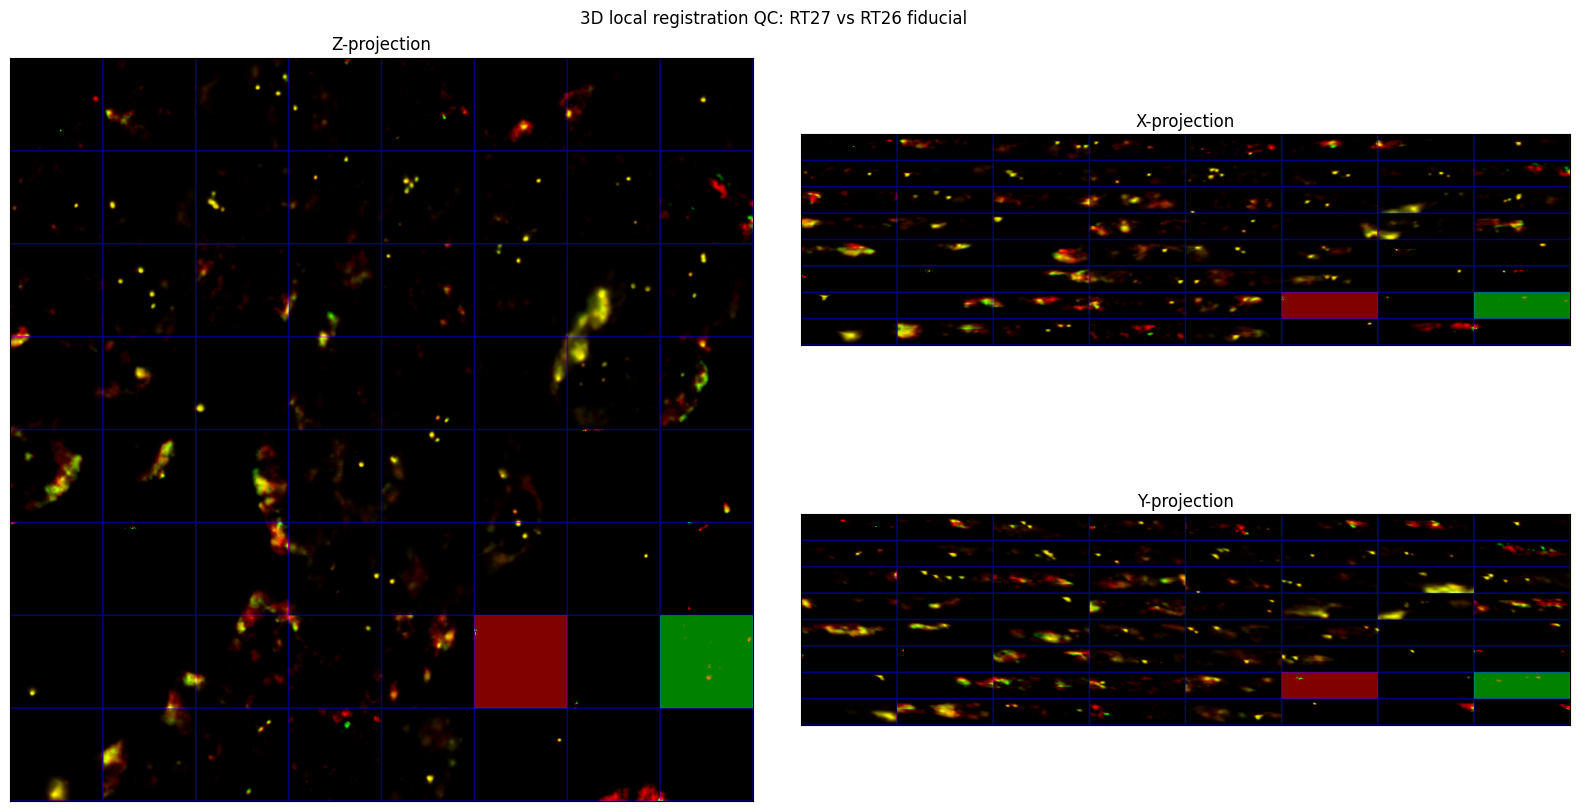

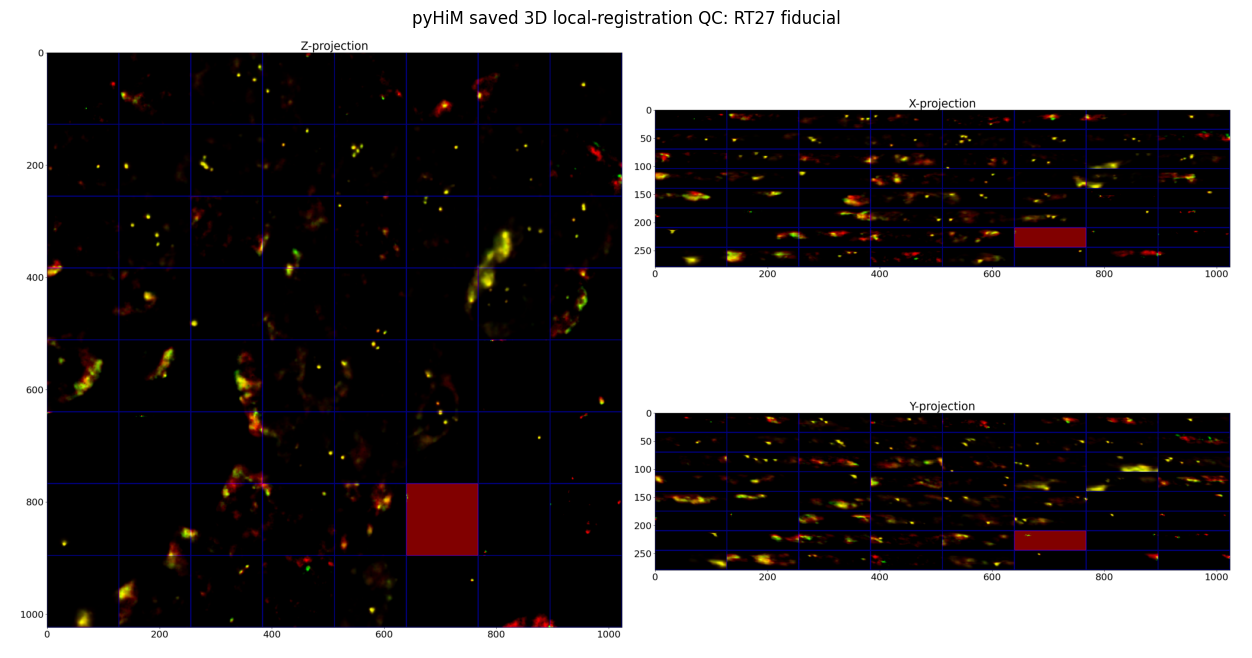

In [11]:
show_local_registration_3d_qc(
    workspace.raw_rounds,
    workspace.local_registration,
    global_registration=workspace.global_registration,
    moving_round=LOCAL_REGISTRATION_3D_QC_ROUND,
    reference_round=REFERENCE_ROUND,
    z_binning=Z_BINNING,
    lower_threshold=0.9,
    higher_threshold=0.9999,
    block_window=LOCAL_REGISTRATION_3D_QC_BLOCK_WINDOW,
    z_projection_crop=LOCAL_REGISTRATION_3D_QC_Z_CROP,
)

qc_image = workspace.raw_rounds[LOCAL_REGISTRATION_3D_QC_ROUND]["fiducial"]
qc_file = Path(qc_image.path).name if qc_image.path else f"{qc_image.name}.tif"
pyhim_3d_qc_png = PYHIM_DIR / "register_local" / f"{qc_file}_3Dalignments.png"
if pyhim_3d_qc_png.exists():
    pyhim_qc = plt.imread(pyhim_3d_qc_png)
    fig, ax = plt.subplots(figsize=(16, 8))
    ax.imshow(pyhim_qc)
    ax.axis("off")
    ax.set_title(f"pyHiM saved 3D local-registration QC: {LOCAL_REGISTRATION_3D_QC_ROUND} fiducial")
else:
    print("Missing pyHiM 3D QC image", pyhim_3d_qc_png)


In [12]:
row = workspace.local_registration.table[
    (workspace.local_registration.table["aligned file"] == "scan_001_DAPI_005_ROI_converted_decon_ch01.tif")
    & (workspace.local_registration.table["block_i"] == 0)
    & (workspace.local_registration.table["block_j"] == 0)
]

row


,reference file,aligned file,blockXY,ROI #,label,block_i,block_j,shift_z,shift_x,shift_y,quality_xy,quality_zy,quality_zx
64,scan_001_RT26_005_ROI_converted_decon_ch00.tif,scan_001_DAPI_005_ROI_converted_decon_ch01.tif,128,5,DAPI,0,0,-4.89,-60.599998,21.129999,0.845346,0.826224,0.660944


## Section 5: Segmentation

In [12]:
# For pyHiM-comparable masks, use globally registered DAPI 2D and
# z-binned, globally shifted DAPI 3D input.
dapi_2d_for_mask = workspace.global_registration.rounds["DAPI"].images["dapi"].registered

dapi_3d_raw = workspace.raw_rounds["DAPI"]["images"]["dapi"].data
shift_yx = workspace.global_registration.rounds["DAPI"].shift
dapi_3d_for_mask = dapi_3d_raw[::Z_BINNING] if "DAPI" == REFERENCE_ROUND else shift_image(
    dapi_3d_raw[::Z_BINNING],
    shift=[0.0, float(shift_yx[0]), float(shift_yx[1])],
)

workspace.masks["mask_2d"] = segment(
    dapi_2d_for_mask,
    method="pyhim",
    background_method="stardist",
    tessellation=False,
    area_min=50,
    area_max=700,
)
workspace.masks["mask_3d"] = segment(
    dapi_3d_for_mask,
    method="pyhim",
)

if SAVE_MODE:
    workspace.save("mask_2d", OUT_DIR / "mask_2d", mode=SAVE_MODE)
    workspace.save("mask_3d", OUT_DIR / "mask_3d", mode=SAVE_MODE)

{name: result.labels.shape for name, result in workspace.masks.items()}


Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.43161, nms_thresh=0.3.


functional.py (238): The structure of `inputs` doesn't match the expected structure.
Expected: ['input']
Received: inputs=Tensor(shape=(1, 1024, 1024, 1))


Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.50019, nms_thresh=0.3.


functional.py (238): The structure of `inputs` doesn't match the expected structure.
Expected: ['input']
Received: inputs=Tensor(shape=(1, 64, 256, 256, 1))
  0%|          | 0/64 [00:00<?, ?it/s]functional.py (238): The structure of `inputs` doesn't match the expected structure.
Expected: ['input']
Received: inputs=Tensor(shape=(1, None, None, None, 1))
100%|██████████| 64/64 [04:02<00:00,  3.78s/it]


{'mask_2d': (1024, 1024), 'mask_3d': (35, 1024, 1024)}

### pyHiM Segmentation Comparison

The pyHiM mask figure is a qualitative QC image: left is the raw DAPI projection, right is the projected label image. It answers whether nuclei-like objects were segmented in plausible places. For equivalence, use quantitative checks as the acceptance criterion: foreground IoU/Dice tell whether the total mask area overlaps, and one-to-one label IoU tells whether individual nuclei match. Label IDs may be renumbered, so exact label values are not expected to match.


,name,shape,dtype,objects,max_label,foreground_px,foreground_fraction
0,pyHiM mask_2d,"(1024, 1024)",int32,24,24,99971,0.095340
1,U-Chrom mask_2d,"(1024, 1024)",int32,6,6,3371,0.003215
2,pyHiM mask_3d,"(35, 1024, 1024)",int32,24,24,621765,0.016942
3,U-Chrom mask_3d,"(35, 1024, 1024)",int32,24,24,621772,0.016942


,step,shape_match,foreground_iou,dice,recall_vs_pyhim,precision_vs_uchrom,pyhim_foreground_px,uchrom_foreground_px
0,mask_2d,True,0.019655,0.038552,0.019926,0.590923,99971,3371
1,mask_3d,True,0.999982,0.999991,0.999997,0.999986,621765,621772


,pyhim_label,uchrom_label,iou,intersection_px,union_px,pyhim_area,uchrom_area,area_ratio_uchrom_over_pyhim
0,1,6,0.000000,0,3146,2546,600,0.235664
1,2,3,0.000000,0,2881,2206,675,0.305984
5,23,4,0.000684,2,2925,2451,476,0.194206
4,17,1,0.017460,44,2520,2237,327,0.146178
3,5,2,0.119371,668,5596,5596,668,0.119371
2,3,5,0.123959,625,5042,5042,625,0.123959


mask_2d mean matched IoU: 0.043578967324023506


,pyhim_label,uchrom_label,iou,intersection_px,union_px,pyhim_area,uchrom_area,area_ratio_uchrom_over_pyhim
23,24,24,0.999880,16627,16629,16628,16628,1.000000
11,12,12,0.999903,30770,30773,30770,30773,1.000097
22,23,23,0.999928,13907,13908,13907,13908,1.000072
0,1,1,0.999932,14683,14684,14683,14684,1.000068
18,19,19,0.999945,18149,18150,18150,18149,0.999945
19,20,20,0.999968,31448,31449,31448,31449,1.000032
14,15,15,0.999969,32413,32414,32413,32414,1.000031
3,4,4,0.999979,47308,47309,47308,47309,1.000021
21,22,22,1.000000,19732,19732,19732,19732,1.000000
20,21,21,1.000000,23333,23333,23333,23333,1.000000


mask_3d mean matched IoU: 0.9999793064709541


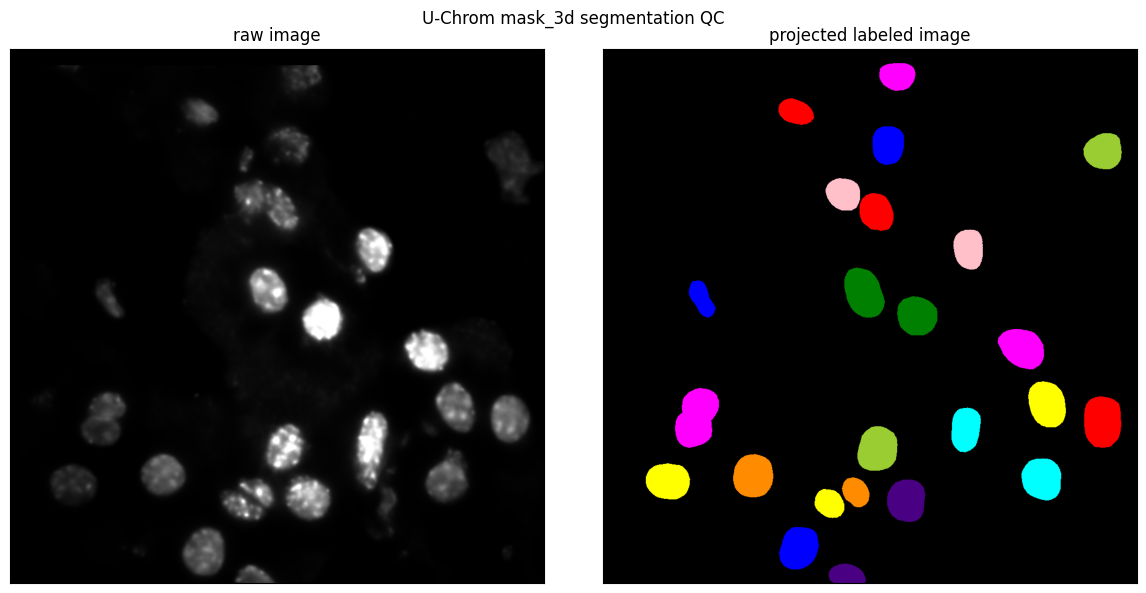

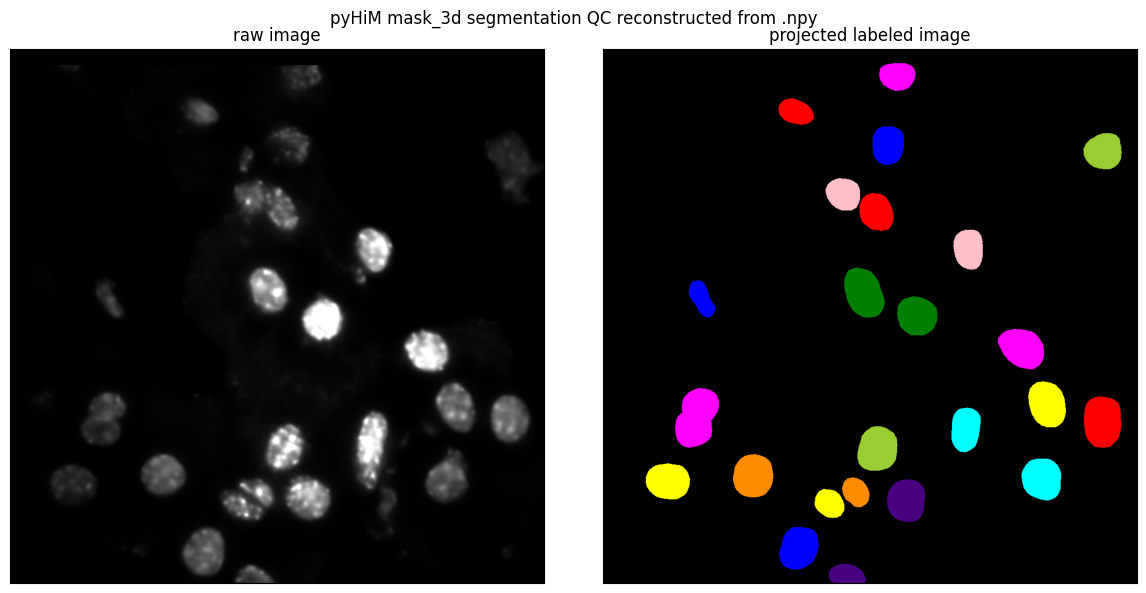

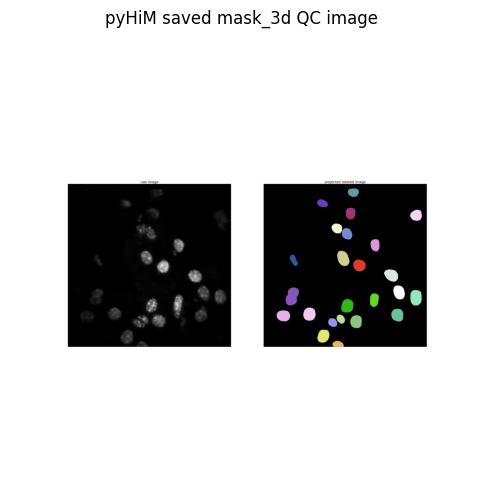

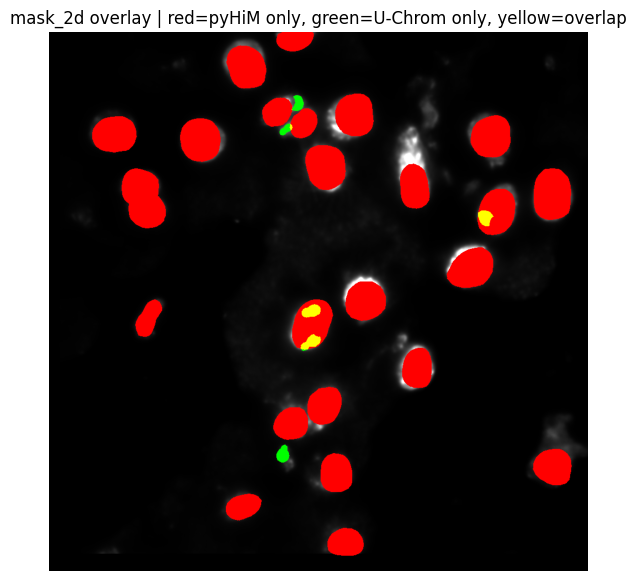

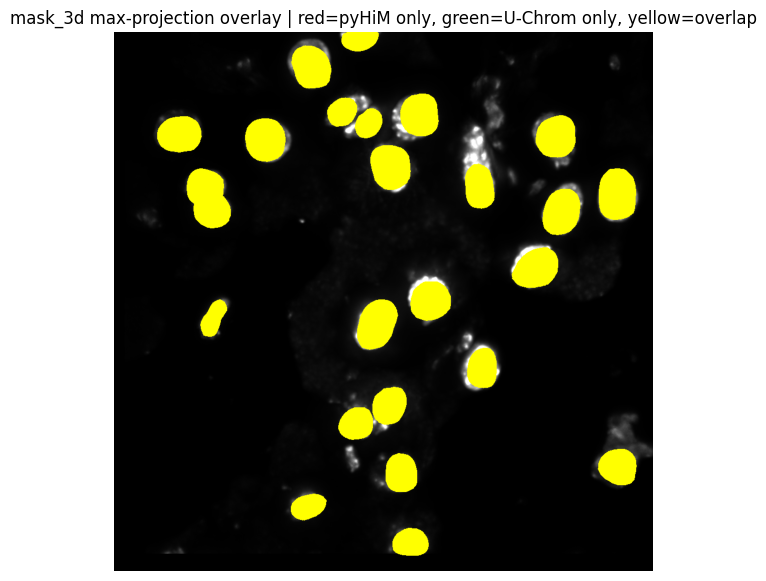

In [13]:
pyhim_mask2d_path = PYHIM_MASK_2D_DATA / "scan_001_DAPI_005_ROI_converted_decon_ch00_Masks.npy"
pyhim_mask3d_path = PYHIM_MASK_3D_DATA / "scan_001_DAPI_005_ROI_converted_decon_ch00_3Dmasks.npy"
pyhim_mask3d_png = PYHIM_DIR / "mask_3d" / "scan_001_DAPI_005_ROI_converted_decon_ch00.tif_3Dmasks.png"

if pyhim_mask2d_path.exists() and pyhim_mask3d_path.exists():
    pyhim_mask2d = np.load(pyhim_mask2d_path)
    pyhim_mask3d = np.load(pyhim_mask3d_path)
    uc_mask2d = workspace.masks["mask_2d"].labels
    uc_mask3d = workspace.masks["mask_3d"].labels

    display(pd.DataFrame([
        mask_summary("pyHiM mask_2d", pyhim_mask2d),
        mask_summary("U-Chrom mask_2d", uc_mask2d),
        mask_summary("pyHiM mask_3d", pyhim_mask3d),
        mask_summary("U-Chrom mask_3d", uc_mask3d),
    ]))
    display(pd.DataFrame([
        {"step": "mask_2d", **foreground_scores(pyhim_mask2d, uc_mask2d)},
        {"step": "mask_3d", **foreground_scores(pyhim_mask3d, uc_mask3d)},
    ]))

    show_mask_segmentation_qc(
        dapi_3d_for_mask,
        uc_mask3d,
        title="U-Chrom mask_3d segmentation QC",
        crop=SEGMENTATION_QC_CROP,
    )
    show_mask_segmentation_qc(
        dapi_3d_for_mask,
        pyhim_mask3d,
        title="pyHiM mask_3d segmentation QC reconstructed from .npy",
        crop=SEGMENTATION_QC_CROP,
    )
    if pyhim_mask3d_png.exists():
        fig, ax = plt.subplots(figsize=(12, 6))
        ax.imshow(plt.imread(pyhim_mask3d_png))
        ax.axis("off")
        ax.set_title("pyHiM saved mask_3d QC image")

    if pyhim_mask2d.shape == uc_mask2d.shape:
        matches_2d = label_iou_matches(pyhim_mask2d, uc_mask2d)
        display(matches_2d)
        print("mask_2d mean matched IoU:", matches_2d["iou"].mean() if len(matches_2d) else None)
        show_mask_overlay(dapi_2d_for_mask, pyhim_mask2d, uc_mask2d, title="mask_2d overlay")
    if pyhim_mask3d.shape == uc_mask3d.shape:
        matches_3d = label_iou_matches(pyhim_mask3d, uc_mask3d)
        display(matches_3d)
        print("mask_3d mean matched IoU:", matches_3d["iou"].mean() if len(matches_3d) else None)
        show_mask_overlay(dapi_3d_for_mask, pyhim_mask3d, uc_mask3d, title="mask_3d max-projection overlay")
else:
    print("Missing pyHiM mask output", pyhim_mask2d_path, pyhim_mask3d_path)


## Section 6: Localization

In [14]:
# For pyHiM-comparable localizations, use z-binned barcode stacks and
# apply the global XY shift before spot detection.
barcode_stacks = {}
for round_name, round_data in workspace.raw_rounds.items():
    if "barcode" not in round_data["images"]:
        continue
    stack = round_data["images"]["barcode"].data[::Z_BINNING]
    if round_name != REFERENCE_ROUND:
        shift_yx = workspace.global_registration.rounds[round_name].shift
        stack = shift_image(stack, shift=[0.0, float(shift_yx[0]), float(shift_yx[1])])
    barcode_stacks[round_name] = stack

workspace.localizations = localize(
    barcode_stacks,
    method="pyhim_3d",
    masks=workspace.masks.get("mask_3d"),
    assign_mask_labels=True,
    roi=ROI,
    backend="stardist",
    reduce_planes=False,
    threshold_over_std=5.0,
    area_min=10,
    area_max=250,
    brightest=1100,
    pixel_size_xy=0.1,
    pixel_size_z=0.25,
    z_binning=Z_BINNING,
    psf_z=500,
    psf_yx=200,
)

if SAVE_MODE:
    workspace.save("localize_3d", OUT_DIR / "localize_3d", mode=SAVE_MODE)

workspace.localizations.head()


Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.537191, nms_thresh=0.4.


functional.py (238): The structure of `inputs` doesn't match the expected structure.
Expected: ['input']
Received: inputs=Tensor(shape=(1, 64, 64, 64, 1))
  0%|          | 0/64 [00:00<?, ?it/s]functional.py (238): The structure of `inputs` doesn't match the expected structure.
Expected: ['input']
Received: inputs=Tensor(shape=(1, None, None, None, 1))
100%|██████████| 64/64 [04:34<00:00,  4.29s/it]


Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.537191, nms_thresh=0.4.


100%|██████████| 64/64 [05:37<00:00,  5.28s/it]


,Buid,ROI #,CellID #,Barcode #,id,zcentroid,xcentroid,ycentroid,sharpness,roundness1,roundness2,npix,sky,peak,flux,mag,round,label
0,8ab48b1d-160a-4d29-a659-9245e1573088,5,0,26,0,5.379947,271.094462,604.618573,0.464286,7.031116,0.464286,182,0.0,44.0,880.0,-7.361207,RT26,RT26
1,b9914271-2646-4391-9edd-7177fc3b936a,5,0,26,1,5.992075,152.443413,630.606600,0.479911,7.432700,0.479911,215,0.0,630.0,12600.0,-10.250926,RT26,RT26
2,b1ee0f44-dc17-42bc-96f9-6354ae21a424,5,0,26,2,6.072535,223.307759,646.451507,0.485185,7.939032,0.485185,262,0.0,99.0,1980.0,-8.241663,RT26,RT26
3,59c8a4c7-ba18-42f1-8e30-a775b199ceb2,5,0,26,3,6.247922,252.756223,697.624655,0.339394,8.116830,0.339394,280,0.0,61.0,1220.0,-7.715900,RT26,RT26
4,b7837855-efee-407b-8270-a861a3f4175e,5,0,26,4,5.480060,131.052579,724.094058,0.430014,8.287163,0.430014,298,0.0,108.0,2160.0,-8.336134,RT26,RT26


### pyHiM Localization Comparison

The pyHiM localization QC image overlays detected barcode spots on a barcode image projection. It is useful for visual sanity checking: spots should sit on bright puncta, and missing/extra detections are often obvious. For quantitative comparison, do not use `Buid`: pyHiM generates UUIDs that are not stable across runs. Instead, compare three things: total spots, spots per barcode, and one-to-one nearest-neighbor distances within each `(ROI, Barcode #)` group. In the distance table, `distance_px` is the 3D distance between matched spots, and `dz/dx/dy` are `U-Chrom - pyHiM` coordinate differences.


,source,n_localizations
0,pyHiM,6919
1,U-Chrom,451


,pyHiM,U-Chrom
Barcode #,,
1,477,0
2,250,0
3,268,0
7,173,0
8,201,0
9,337,0
10,358,0
11,192,0
12,258,0


,pyhim_total,uchrom_total,matched,pyhim_match_rate,uchrom_match_rate,median_distance_px,p95_distance_px
0,6919,451,451,0.065183,1.0,393.308565,920.16722


,ROI #,Barcode #,pyhim_index,uchrom_index,distance_px,dz,dx,dy
204,5,27,1780,262,5.143148,2.129909,-1.931162,-4.264514
244,5,27,1833,221,10.250396,-3.405393,1.843128,-9.490880
97,5,26,6134,22,18.805380,-7.164573,-17.098126,-3.156783
3,5,26,6021,63,21.473547,1.293714,-14.917791,-15.391524
425,5,27,2074,220,26.065957,-8.342029,-16.801219,-18.098722
69,5,26,6099,96,26.595263,2.112855,14.526656,22.177018
340,5,27,1963,373,29.610888,4.784261,7.529251,-28.235189
434,5,27,2097,309,30.084822,-3.680258,-3.469432,-29.656622
200,5,27,1772,386,33.505532,11.500551,-14.677008,-27.837805
371,5,27,2007,450,35.406707,16.927287,7.136401,30.268361


,ROI #,Barcode #,pyhim_index,uchrom_index,distance_px,dz,dx,dy
24,5,26,6051,187,1359.897445,18.576065,-1330.646511,-279.921154
96,5,26,6126,23,1248.529747,-5.798878,-855.409754,-909.432271
119,5,26,6157,121,1226.758069,2.442538,-918.076782,-813.673409
164,5,26,6213,86,1149.001663,-1.774986,-925.534725,-680.872339
387,5,27,2027,265,1141.552047,-4.182653,-688.352990,-910.655666
307,5,27,1914,399,1111.916596,8.734553,-760.586641,-811.042654
335,5,27,1957,446,1094.771413,16.590566,-876.132977,-656.231824
17,5,26,6039,112,1092.106752,6.027873,-811.564279,-730.769625
416,5,27,2062,441,1062.314308,11.306886,-852.622665,-633.575910
197,5,27,1766,248,1050.155897,1.405244,-865.779175,-594.349942


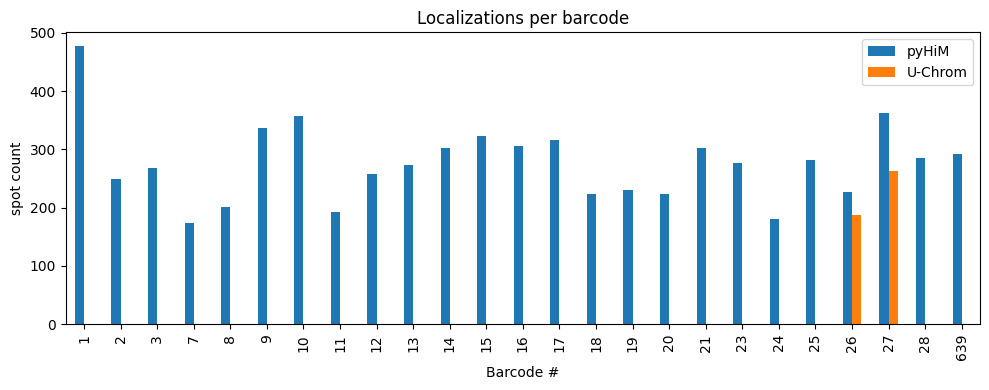

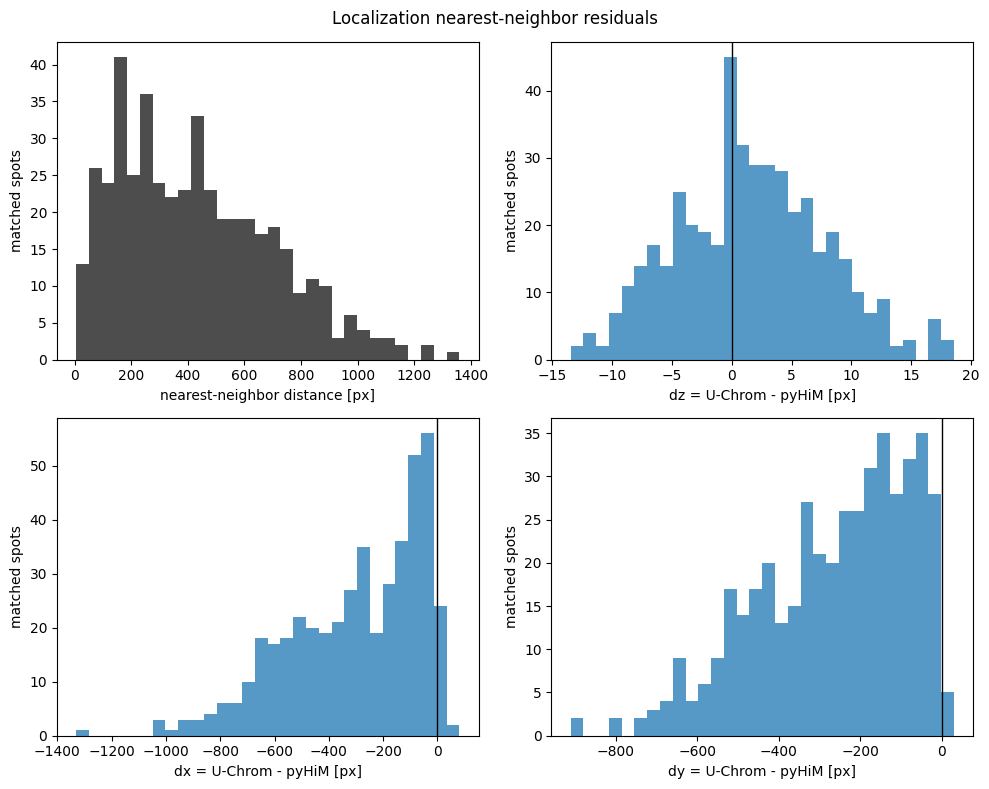

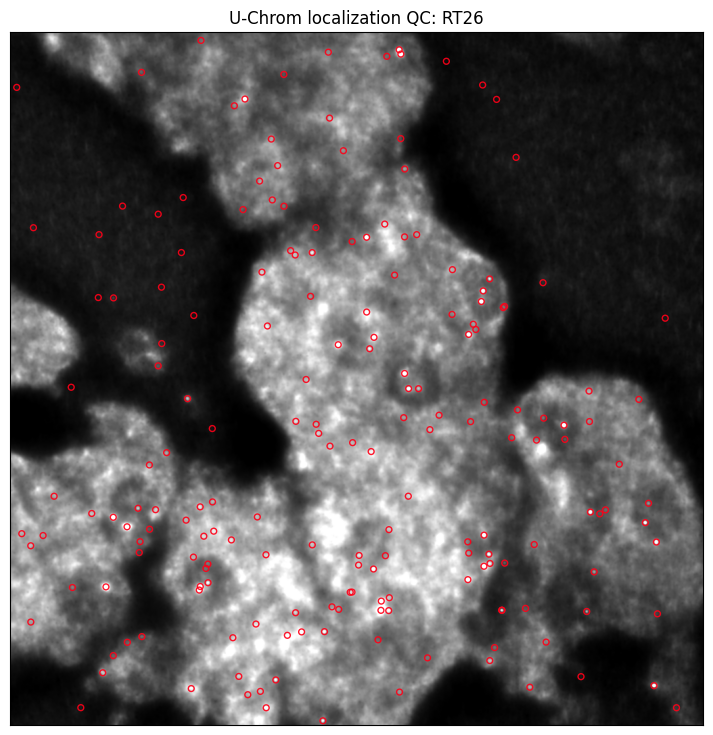

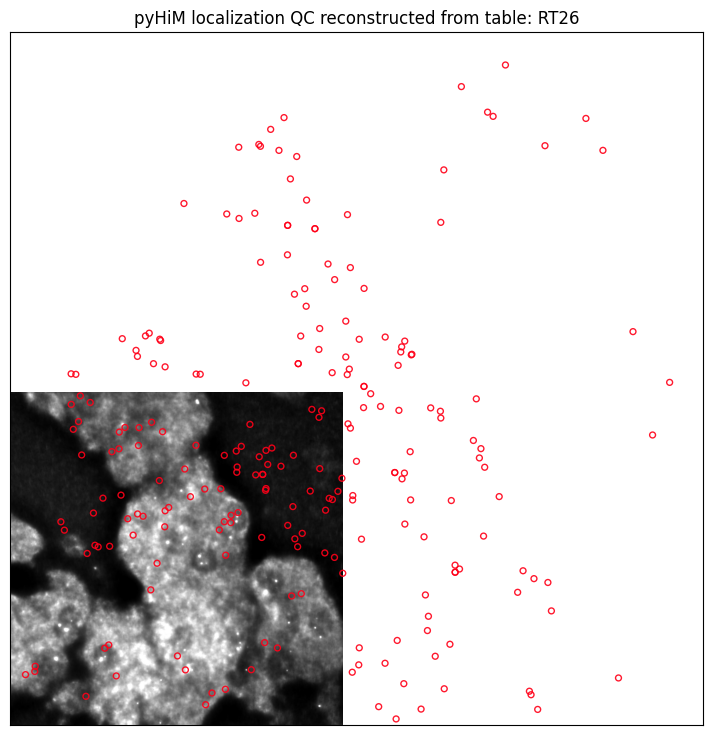

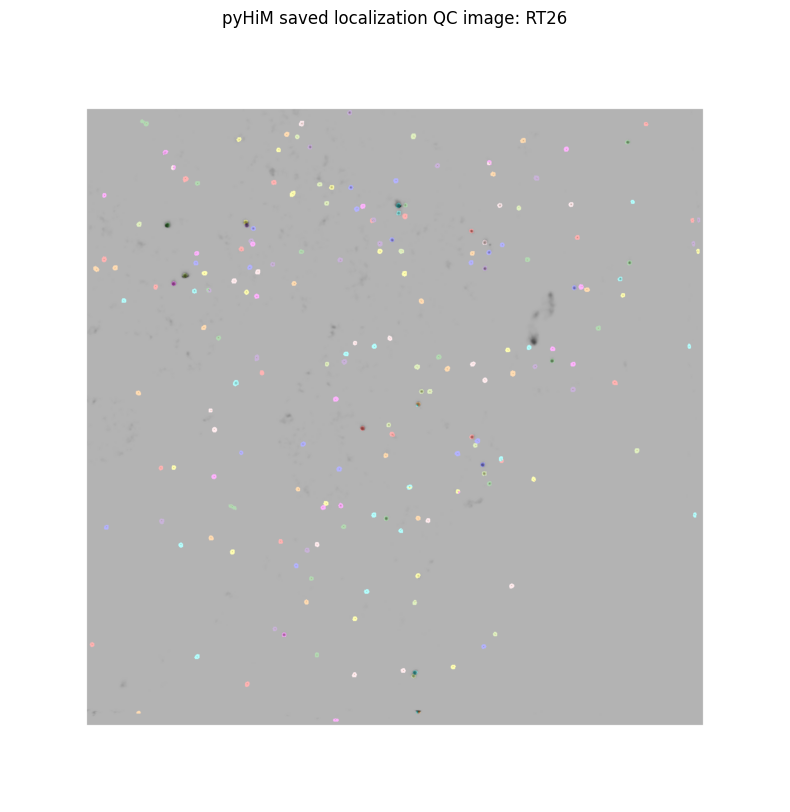

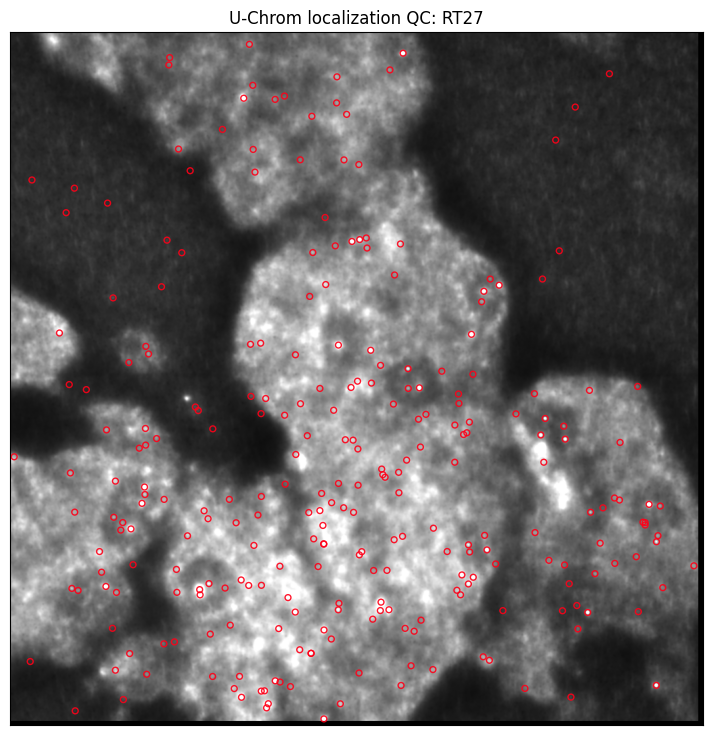

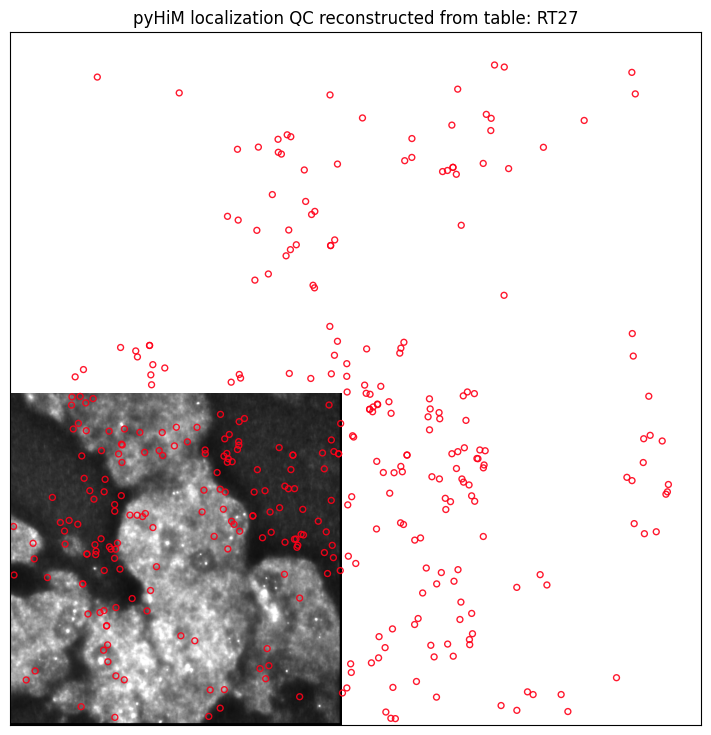

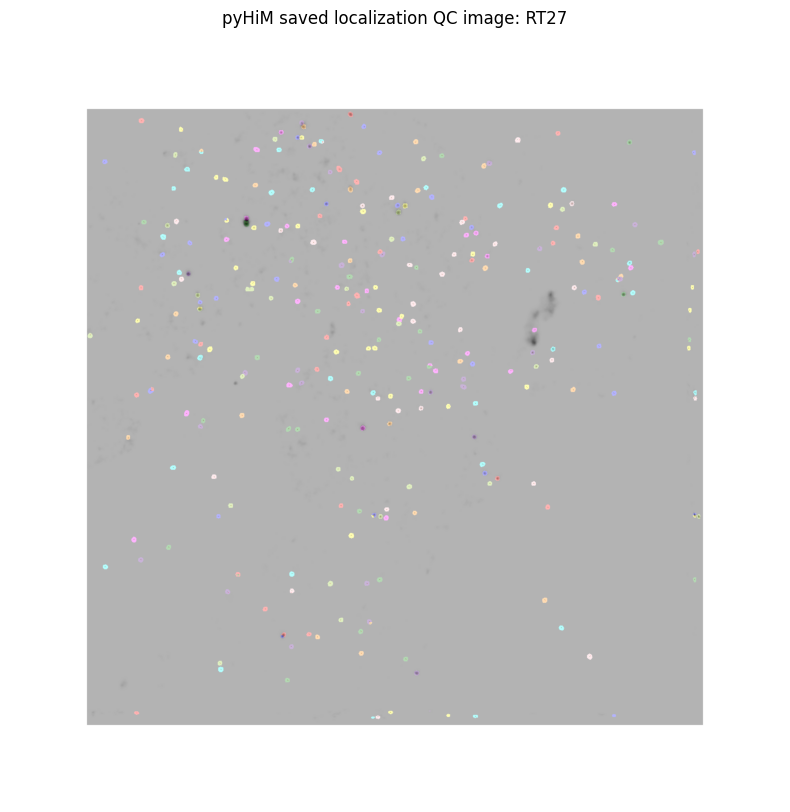

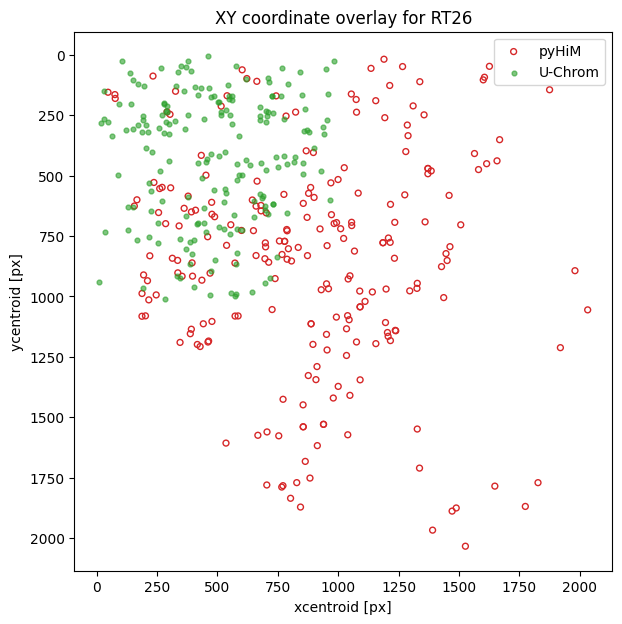

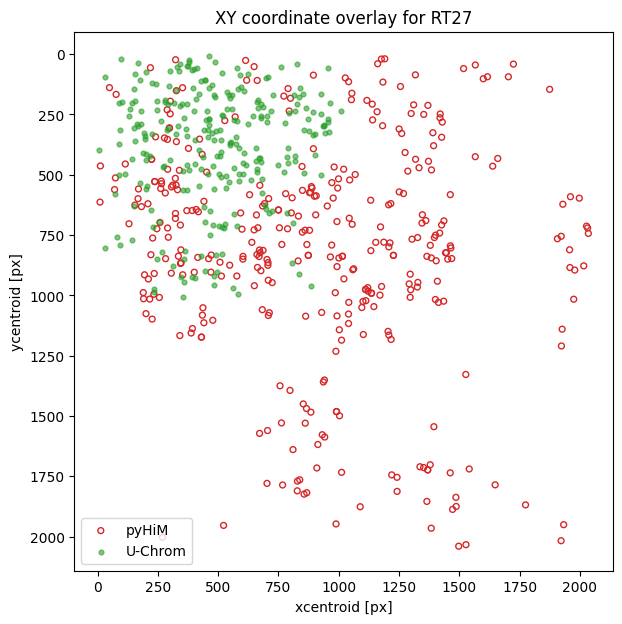

In [16]:
if PYHIM_LOCALIZE_3D_PATH is not None and PYHIM_LOCALIZE_3D_PATH.exists():
    pyhim_locs = read_ecsv(PYHIM_LOCALIZE_3D_PATH)
    uc_locs = workspace.localizations.table

    count_summary, barcode_counts = localization_count_summary(pyhim_locs, uc_locs)
    display(count_summary)
    display(barcode_counts)
    if not barcode_counts.empty:
        barcode_counts.plot(kind="bar", figsize=(10, 4), title="Localizations per barcode")
        plt.ylabel("spot count")
        plt.tight_layout()

    loc_matches, loc_summary = match_localizations_by_position(pyhim_locs, uc_locs, max_distance_px=None)
    display(pd.DataFrame([loc_summary]))
    display(loc_matches.sort_values("distance_px").head(20))
    display(loc_matches.sort_values("distance_px", ascending=False).head(20))
    show_localization_match_diagnostics(loc_matches, title="Localization nearest-neighbor residuals")

    for round_name, barcode in [("RT26", 26), ("RT27", 27)]:
        stack = barcode_stacks.get(round_name)
        if stack is None:
            continue
        show_barcode_localization_qc(
            stack,
            uc_locs,
            barcode=barcode,
            title=f"U-Chrom localization QC: {round_name}",
            crop=LOCALIZATION_QC_CROP,
        )
        show_barcode_localization_qc(
            stack,
            pyhim_locs,
            barcode=barcode,
            title=f"pyHiM localization QC reconstructed from table: {round_name}",
            crop=LOCALIZATION_QC_CROP,
        )
        qc_image = workspace.raw_rounds[round_name]["images"]["barcode"]
        qc_file = Path(qc_image.path).name if qc_image.path else f"{qc_image.name}.tif"
        pyhim_loc_png = PYHIM_DIR / "localize_3d" / f"{qc_file}_3DimageNlocalizations.png"
        if pyhim_loc_png.exists():
            fig, ax = plt.subplots(figsize=(10, 10))
            ax.imshow(plt.imread(pyhim_loc_png))
            ax.axis("off")
            ax.set_title(f"pyHiM saved localization QC image: {round_name}")

    plot_localization_xy(pyhim_locs, uc_locs, barcode=26, title="XY coordinate overlay for RT26")
    plot_localization_xy(pyhim_locs, uc_locs, barcode=27, title="XY coordinate overlay for RT27")
else:
    print("Missing pyHiM localization table", PYHIM_LOCALIZE_3D_PATH)


In [ ]:
row = workspace.localizations.table[
    (workspace.localizations.table["Barcode #"] == 26)
]

row

## Section 7: Trace / Matrix

In [17]:
filtered = filter_localizations(workspace.localizations, flux_min_3D=10.0)

registered_locs = register_localizations(
    filtered,
    global_registration=workspace.global_registration,
    local_registration=workspace.local_registration,
    tolerance_drift=LOCALIZATION_TOLERANCE_DRIFT,
    remove_uncorrected_localizations=REMOVE_UNCORRECTED_LOCALIZATIONS,
)

workspace.traces = build_traces(
    registered_locs,
    masks=workspace.masks.get("mask_3d"),
    method="KDtree",
    distance_threshold_um=1.0,
    pixel_size_xy=0.1,
    pixel_size_z=0.25,
    roi=ROI,
)

workspace.matrices = build_matrix(workspace.traces)

if SAVE_MODE:
    workspace.save("tracing", OUT_DIR / "tracing", mode=SAVE_MODE)
    workspace.save("matrix", OUT_DIR / "matrix", mode=SAVE_MODE)

workspace.matrices.matrices.keys()

dict_keys(['PWDscMatrix', 'Nmatrix', 'uniqueBarcodes'])

### pyHiM Trace And Matrix Comparison

This section checks whether localization differences propagate into chromatin traces and distance matrices. `Trace_ID` values are implementation-specific, so equality of IDs is not expected. First compare trace table scale: number of rows, number of traces, median spots per trace and rows per barcode. Then compare matrices on the same barcode set. pyHiM stores `PWDscMatrix` as `(barcode, barcode, trace/cell)`, so it is collapsed with `nanmedian(axis=2)` before comparing to U-Chrom?s current median matrix. `Nmatrix` is the number of observations per barcode pair.


,source,rows,unique_traces,median_spots_per_trace,unique_barcodes
0,pyHiM,6917,3519,1.0,25
1,U-Chrom,249,194,1.0,2


,pyHiM,U-Chrom
Barcode #,,
1,477,0
2,250,0
3,268,0
7,173,0
8,201,0
9,337,0
10,358,0
11,192,0
12,258,0


d:\Miniconda3\envs\uchrom\lib\site-packages\numpy\lib\nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,


,pyhim_matrix_shape,uchrom_matrix_shape,pyhim_barcodes,uchrom_barcodes,common_barcodes
0,"(25, 25)","(2, 2)","[1, 2, 3, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,...","[26, 27]","[26, 27]"


,matrix,shape_reference,shape_candidate,dtype_reference,dtype_candidate,shape_match,finite_fraction,exact_equal,max_abs_diff,mean_abs_diff,rmse,nrmse_by_ref_range,pearson,finite_overlap_fraction
0,PWDscMatrix median on common barcodes,"(2, 2)","(2, 2)",float64,float64,True,0.5,False,0.060474,0.060474,0.060474,NaN,NaN,0.5
1,Nmatrix on common barcodes,"(2, 2)","(2, 2)",int32,float64,True,1.0,False,127.000000,70.000000,87.272562,1.28342,-0.995212,1.0


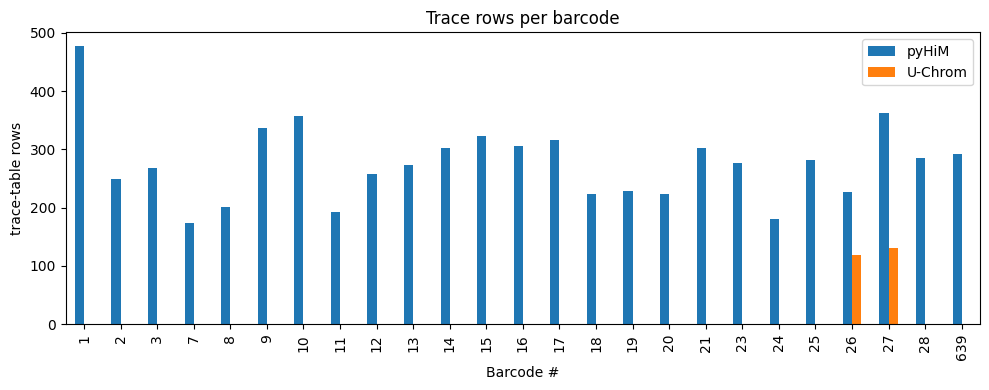

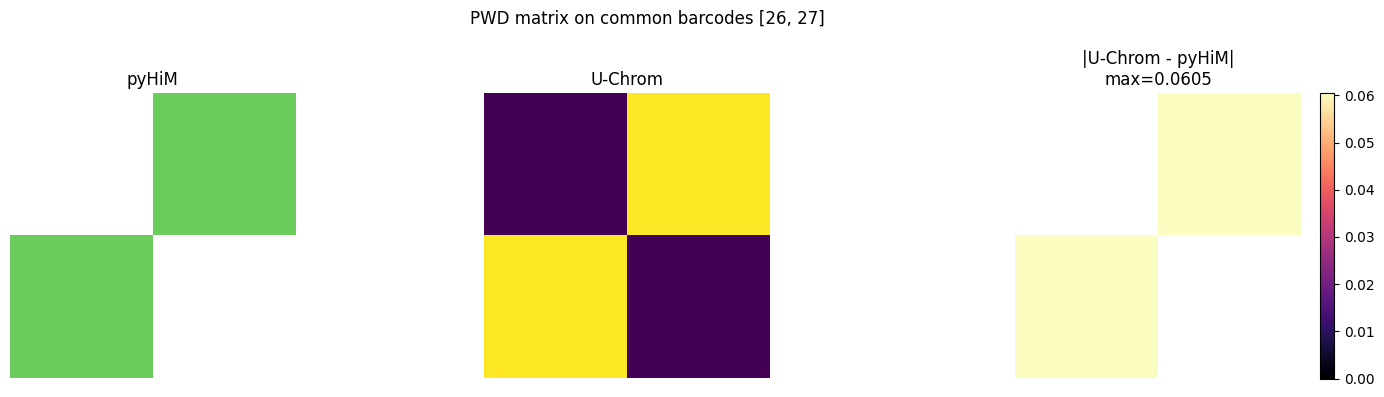

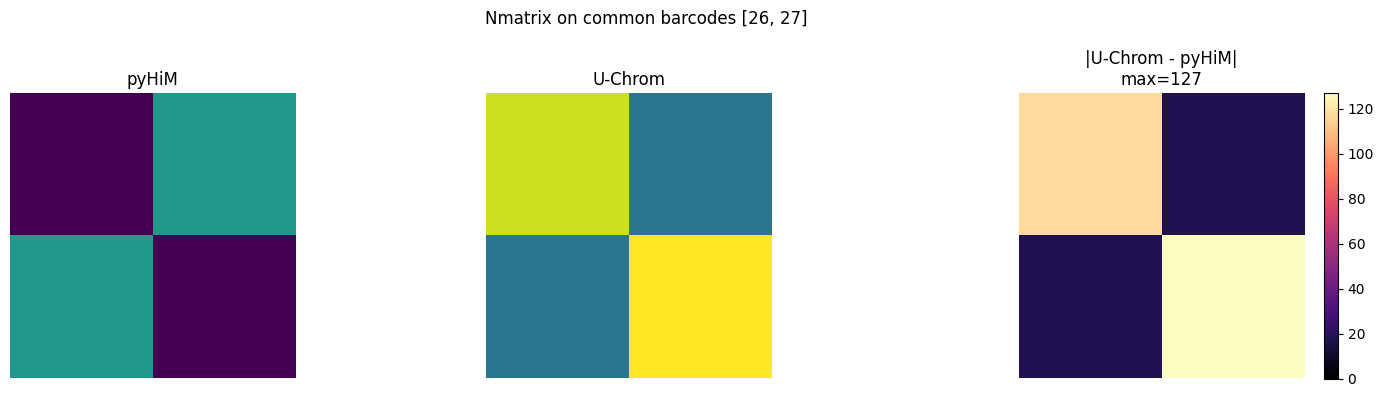

In [18]:
pyhim_trace_path = PYHIM_TRACE_DATA / "Trace_3D_barcode_KDtree_ROI-5.ecsv"
pyhim_pwd_path = PYHIM_TRACE_DATA / "Trace_3D_barcode_KDtree_ROI-5_Matrix_PWDscMatrix.npy"
pyhim_nmatrix_path = PYHIM_TRACE_DATA / "Trace_3D_barcode_KDtree_ROI-5_Matrix_Nmatrix.npy"
pyhim_unique_path = PYHIM_TRACE_DATA / "Trace_3D_barcode_KDtree_ROI-5_Matrix_uniqueBarcodes.ecsv"

if pyhim_trace_path.exists() and workspace.traces is not None:
    pyhim_traces = read_ecsv(pyhim_trace_path)
    uc_traces = workspace.traces.table
    display(pd.DataFrame([trace_summary(pyhim_traces, "pyHiM"), trace_summary(uc_traces, "U-Chrom")]))
    if "Barcode #" in pyhim_traces and "Barcode #" in uc_traces:
        trace_counts = pd.concat([
            pd.to_numeric(pyhim_traces["Barcode #"], errors="coerce").value_counts().sort_index().rename("pyHiM"),
            pd.to_numeric(uc_traces["Barcode #"], errors="coerce").value_counts().sort_index().rename("U-Chrom"),
        ], axis=1).fillna(0).astype(int)
        display(trace_counts)
        trace_counts.plot(kind="bar", figsize=(10, 4), title="Trace rows per barcode")
        plt.ylabel("trace-table rows")
        plt.tight_layout()
else:
    print("Missing pyHiM trace table or U-Chrom trace result", pyhim_trace_path)

if pyhim_pwd_path.exists() and pyhim_nmatrix_path.exists() and workspace.matrices is not None:
    pyhim_pwd_raw = np.load(pyhim_pwd_path)
    pyhim_pwd_median = np.nanmedian(pyhim_pwd_raw, axis=2) if pyhim_pwd_raw.ndim == 3 else pyhim_pwd_raw
    pyhim_nmatrix = np.load(pyhim_nmatrix_path)
    pyhim_barcodes = np.atleast_1d(np.loadtxt(pyhim_unique_path, dtype=int)) if pyhim_unique_path.exists() else np.arange(pyhim_pwd_median.shape[0])

    uc_pwd = workspace.matrices["PWDscMatrix"]
    uc_nmatrix = workspace.matrices["Nmatrix"]
    uc_barcodes = np.asarray(workspace.matrices["uniqueBarcodes"], dtype=int)
    common_barcodes = [int(b) for b in uc_barcodes if int(b) in set(pyhim_barcodes.astype(int))]
    display(pd.DataFrame([{
        "pyhim_matrix_shape": pyhim_pwd_median.shape,
        "uchrom_matrix_shape": uc_pwd.shape,
        "pyhim_barcodes": list(pyhim_barcodes.astype(int)),
        "uchrom_barcodes": list(uc_barcodes.astype(int)),
        "common_barcodes": common_barcodes,
    }]))

    if common_barcodes:
        py_idx = [int(np.where(pyhim_barcodes.astype(int) == b)[0][0]) for b in common_barcodes]
        uc_idx = [int(np.where(uc_barcodes.astype(int) == b)[0][0]) for b in common_barcodes]
        pyhim_pwd_common = pyhim_pwd_median[np.ix_(py_idx, py_idx)]
        uc_pwd_common = uc_pwd[np.ix_(uc_idx, uc_idx)]
        pyhim_nmatrix_common = pyhim_nmatrix[np.ix_(py_idx, py_idx)]
        uc_nmatrix_common = uc_nmatrix[np.ix_(uc_idx, uc_idx)]
        display(pd.DataFrame([
            {"matrix": "PWDscMatrix median on common barcodes", **matrix_metrics(pyhim_pwd_common, uc_pwd_common)},
            {"matrix": "Nmatrix on common barcodes", **matrix_metrics(pyhim_nmatrix_common, uc_nmatrix_common)},
        ]))
        show_matrix_comparison(pyhim_pwd_common, uc_pwd_common, title=f"PWD matrix on common barcodes {common_barcodes}")
        show_matrix_comparison(pyhim_nmatrix_common, uc_nmatrix_common, title=f"Nmatrix on common barcodes {common_barcodes}")
    else:
        print("No common barcodes between pyHiM and U-Chrom matrices; matrix values cannot be compared yet.")
else:
    print("Missing pyHiM matrix outputs or U-Chrom matrix result")


## Section 8: Current Alignment Status

Current implementation status relative to pyHiM:

- Projection and 2D global registration are the closest to pyHiM and can be judged with pixel-wise metrics.
- 3D local registration is now migrated through the pyHiM block3D path: U-Chrom estimates per-block `shift_z/shift_x/shift_y`, computes projection NRMSE quality matrices, and applies per-block shifts during localization registration with pyHiM-style `toleranceDrift` and `remove_uncorrected_localizations`.
- Segmentation now has a pyHiM-aligned backend under `method="pyhim"`. The acceptance check is still the same: use mask IoU and label matching against pyHiM outputs.
- Localization now has a pyHiM-aligned 3D backend under `method="pyhim_3d"`, with pyHiM StarDist/threshold segmentation and apifish sub-pixel fitting when the optional dependencies are installed. `Buid` should not be used for cross-tool matching.
- Trace/matrix is structurally compatible but not fully output-equivalent. U-Chrom currently returns a 2D median PWD matrix, while pyHiM stores a per-trace PWD stack plus derived matrices.

Use the comparison cells above as acceptance checks. When a step fails, first check input equivalence, then algorithm equivalence, then output-format equivalence.
